<style>
/* Persian text styling */
.jp-RenderedHTMLCommon, .rendered_html, .markdown-body, .jp-MarkdownOutput {
    font-family: Vazir, Tahoma, sans-serif !important;
}
</style>

<div dir="rtl" style="text-align: center; padding: 20px; font-family: Vazir, Tahoma, sans-serif;">
  <h1 style="margin: 0; font-size: 30px;">
    تکلیف ۲: تشخیص لهجه‌ها و گویش‌های ایرانی با شبکه ابداعی Parity-Net
  </h1>
  <p style="margin-top: 12px; font-size: 16px; color: #555;">
    Word Embeddings • PyTorch • Custom Neural Architectures • NLP
  </p>
</div>

<hr style="border-color: #334155;">

<div dir="rtl" style="text-align: right; line-height: 2; padding: 18px; background-color: #0f172a; color: #f8fafc; border-radius: 14px; font-family: Vazir, Tahoma, sans-serif;">

<b>شیوه‌ی تحویل:</b> ارسال فایل کامل همین نوت‌بوک.<br>
<b>نحوه‌ی نمره‌دهی:</b> بخش اصلی نمره بر اساس درستی پیاده‌سازی‌ها است و بخشی هم به خوانایی و کارایی کد اختصاص دارد. هر بخش از 5 بخش ابتدایی این تمرین 20% نمره را دارد. همچنین پاسخ به بخش 6 اُم نیز 10% نمره اضافی در پی خواهد داشت (110% در مجوع). علاوه بر این‌ها نمره‌اضافی تا 10% بیشتر بسته به کیفیت خروجی، ابداع و تحلیل شما ممکن است تعلق بگیرد.<br>
<b>نسخه‌ی پیشنهادی پایتون:</b> Python 3.12 </br>
<b>مجموعه داده‌ی استفاده شده: </b>فایل داده‌ی همراه با نام <code>sentiment_data.csv</code> در همان پوشه‌ی نوت‌بوک. منبع مجموعه دادگان  <a href="https://github.com/SilkRoadAparsin/Sentiment/tree/main/datasets">این مخزن</a> است. توجه فرمائید که از نسخه‌ای استفاده کنید که در کنار نوت‌بوک برای شما قرار داده شده است. </br>
<b>نکات مهم:</b>
استفاده از هوش مصنوعی نه‌تنها مجاز است، بلکه توصیه می‌شود؛ با این حال، باید بر خروجی آن مسلط باشید و آن را به‌طور کامل درک کرده باشید. همچنین استفاده از اینترنت بلامانع است، اما مشورت با هم‌کلاسی‌ها یا استفاده از پاسخ‌های آن‌ها مجاز نیست و این موضوع بررسی خواهد شد. هدف از طراحی این تمرین، سنجش میزان دانش شما از درس و قدرت تحلیل شماست. در پایان، از برخی دانشجویان ارائه‌ی مجازی گرفته خواهد شد تا اطمینان حاصل شود که پاسخ‌های نوشته شده را کامل درک کرده‌اید و توانایی حل مسائل را دارید.

<hr style="border-color: #334155;">

<b>اجرای محلی (Local):</b><br>
برای اجرای این تکلیف روی سیستم شخصی، فقط این موارد را لازم دارید:
<ul style="margin-top: 8px;">
  <li>Python 3.11 یا بالاتر</li>
  <li>Jupyter Notebook یا JupyterLab</li>
  <li>فایل نوت‌بوک</li>
  <li>فایل داده‌ی همراه با نام <code>sentiment_data.csv</code> در همان پوشه‌ی نوت‌بوک</li>
</ul>

سپس نوت‌بوک را باز کنید و مطمئن شوید فایل <code>sentiment_data.csv</code> کنار آن قرار دارد. ممکن است نیاز باشد برخی کتابخانه‌های پایتون را دانلود کنید. اگر امکان اتصال به مخزن اصلی پایتون را نداشتید، طبق راهنمایی موجود در <a href="https://docs.parspack.com/reference/mirror/pypi-pip/">این لینک</a>، از مخزن داخلی استفاده کنید.
</div>

<hr style="border-color: #334155;">

## <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">اطلاعات کلی</div>

<div dir="rtl" style="text-align: right; line-height: 2; padding: 18px; background-color: #0f172a; color: #f8fafc; border-radius: 14px; font-family: Vazir, Tahoma, sans-serif;">
<b>هدف تمرین:</b> آشنایی با پیاده‌سازی شبکه‌های عصبی پیش‌خور (Feed-Forward) و لایه‌های Embedding در PyTorch برای طبقه‌بندی متن.<br>
<b>قوانین اجرا:</b> تمرین طوری طراحی شده است که نیازی به استفاده از GPU نداشته باشد. فایل دیتاست <code>sentiment_data.csv</code> در کنار نوت‌بوک قرار دارد و نیازی به اینترنت برای دانلود دیتا یا مدل‌های از پیش آموزش‌دیده (Pre-trained) ندارید.<br>
<b>معماری ابداعی:</b> در این تمرین، شما از معماری استانداردی استفاده نمی‌کنید. شبکه شما باید کلمات را بر اساس «زوج یا فرد بودن تعداد حروفشان» تفکیک کند که جزئیات آن در بخش‌های بعدی آمده است.

</div>

### <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">بخش ۱: تحلیل و پیش‌پردازش دادگان (Data Analysis & Preprocessing)</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
در اولین گام، باید با دادگانی که در اختیار دارید آشنا شوید. فایل <code>sentiment_data.csv</code> حاوی جملاتی از زبان‌ها، گویش‌ها و لهجه‌های مختلف ایرانی است. 
<br><br>
<b>وظایف شما در این بخش:</b>
<ol>
    <li>فایل دادگان را با استفاده از کتابخانه Pandas بارگذاری کرده و چند سطر نخست آن را برای آشنایی با ساختار ستون‌ها نمایش دهید. توجه فرمائید که هدف پیش‌بینی مادیر ستون <b>accent</b> با استفاده از ستون text یا transliteration یا هر دو است (تصمیم گیری با خودتان!).</li>
    <li><b>تحلیل داده‌ها:</b> تحلیل‌های اکتشافی (EDA) متنوعی را که برای شناخت بهتر مجموعه داده مفید می‌دانید، روی آن انجام دهید. می‌توانید از تکنیک‌های مصورسازی نیز کمک بگیرید. خلاقیت شما در این بخش ارزیابی شده و دارای نمره است.</li>
    <li><b>پیش‌پردازش:</b> اکنون که با داده‌ها آشنا شدید، بررسی کنید که آیا پیش‌پردازش خاصی برای استفاده از آن‌ها نیاز است؟ آیا می‌توان از تمام دادگان به همین شکل استفاده کرد؟ در صورت نیاز، گام‌های پیش‌پردازش (مانند مدیریت مقادیر تهی، حذف یا اصلاح داده‌های نویزی، یکسان‌سازی حروف و پاک‌سازی متن) را پیاده‌سازی و اعمال کنید. (توصیه می‌شود این بخش را هم‌زمان با پیش‌روی در گام‌های بعدی و شناخت نیازهای مدل خود تکمیل کنید.)</li>
    <li>
    تقسیم به دسته‌های آموزش و ارزیابی (و در صورت نیاز به اعتبار سنجی)
    </li>
</ol>
</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

from transformers import AutoTokenizer

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim

In [3]:
# read the data and see head
df = pd.read_csv('sentiment_data.csv')
df.head()

,language,dialect,accent,text,transliteration,sentiment_1,sentiment_2,sentiment_3
0,Caspian,Mazandarani,Tonekaboni,داره بوشُم,dare bushom,neutral,neutral,neutral
1,Caspian,Mazandarani,Tonekaboni,خرس اَنه بوخاره، ترکنه (اینه مو ریزنه),"khers ane bokhare, terkene (ine mu rizene)",negative,negative,negative
2,Caspian,Mazandarani,Tonekaboni,مِره وشنایه,mere vashnāye,negative,neutral,negative
3,Caspian,Mazandarani,Tonekaboni,چای نوخارنُم,chāi nokharnom,neutral,negative,neutral
4,Caspian,Mazandarani,Tonekaboni,عالی با؛ ماچ تی جان، تی قربان بوشُم,"āli bā; māch ti jān, ti ghorbān boshum",positive,positive,positive


In [4]:
# see nan counts of each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   language         800 non-null    object
 1   dialect          800 non-null    object
 2   accent           800 non-null    object
 3   text             601 non-null    object
 4   transliteration  600 non-null    object
 5   sentiment_1      701 non-null    object
 6   sentiment_2      701 non-null    object
 7   sentiment_3      701 non-null    object
dtypes: object(8)
memory usage: 50.1+ KB


In [5]:
# find where text is nan
df[df['text'].isna()]

,language,dialect,accent,text,transliteration,sentiment_1,sentiment_2,sentiment_3
400,"Dari, Zoroastrian","Dari, Zoroastrian",Yazdi,NaN,dāroshe,positive,positive,neutral
401,"Dari, Zoroastrian","Dari, Zoroastrian",Yazdi,NaN,khers o ro vakhra traka,negative,negative,negative
402,"Dari, Zoroastrian","Dari, Zoroastrian",Yazdi,NaN,vāshnama,negative,negative,negative
403,"Dari, Zoroastrian","Dari, Zoroastrian",Yazdi,NaN,me chāyi nakhre,neutral,neutral,neutral
404,"Dari, Zoroastrian","Dari, Zoroastrian",Yazdi,NaN,"kheyli khib bo, buch var junod, korbunod be.",positive,positive,postive
...,...,...,...,...,...,...,...,...
594,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
595,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
596,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
597,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN


In [6]:
# find where transliteration is nan
df[df['transliteration'].isna()]

,language,dialect,accent,text,transliteration,sentiment_1,sentiment_2,sentiment_3
73,Caspian,Mazandarani,Tonekaboni,چه ره ری؟,NaN,neutral,neutral,neutral
500,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
501,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
502,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
503,Persian,"Persian, Iranian",Isfahani,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
795,Pashto,Pashto,Pakistani,غلام د تورې ورېځې سره راغی او جینۍ یې د پریو م...,NaN,neutral,positive,neutral
796,Pashto,Pashto,Pakistani,دا ویب ډېر ښکلی دی,NaN,positive,negative,positive
797,Pashto,Pashto,Pakistani,زه غواړم خپل ګریبان وشلوم (د ناامیدۍ/غصې له امله),NaN,negative,neutral,negative
798,Pashto,Pashto,Pakistani,ستا کار برباد شي,NaN,negative,positive,negative


In [7]:
# drop where both text and transliteration are nan
df.dropna(subset=['text', 'transliteration'], thresh=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 701 entries, 0 to 799
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   language         701 non-null    object
 1   dialect          701 non-null    object
 2   accent           701 non-null    object
 3   text             601 non-null    object
 4   transliteration  600 non-null    object
 5   sentiment_1      701 non-null    object
 6   sentiment_2      701 non-null    object
 7   sentiment_3      701 non-null    object
dtypes: object(8)
memory usage: 49.3+ KB


In [8]:
# value counts of first 3 columns
df['language'].value_counts(), df['dialect'].value_counts(), df['accent'].value_counts()

(language
 Persian              101
 Caspian              100
 Kurdish              100
 Unclassified         100
 Semnani              100
 Dari, Zoroastrian    100
 Pashto               100
 Name: count, dtype: int64,
 dialect
 Persian, Iranian     101
 Mazandarani          100
 Southern Kurdish     100
 Dezfuli              100
 Semnani              100
 Dari, Zoroastrian    100
 Pashto               100
 Name: count, dtype: int64,
 accent
 Tonekaboni          100
 Southern Kurdish    100
 Dezfuli             100
 Semnani             100
 Yazdi               100
 Shirazi             100
 Pakistani           100
 Isfahani              1
 Name: count, dtype: int64)

In [9]:
# Isfahani has only 1 sample, so it won't be useful
df.drop(df[df['accent'] == 'Isfahani'].index, inplace=True)

In [10]:
# drop duplicated if exists
df.drop_duplicates(inplace=True)

In [11]:
# see some statistical description of columns
df.describe()

,language,dialect,accent,text,transliteration,sentiment_1,sentiment_2,sentiment_3
count,700,700,700,600,599,700,700,700
unique,7,7,7,600,597,4,3,4
top,Caspian,Mazandarani,Tonekaboni,داره بوشُم,golo bolbolo sonbol,negative,negative,negative
freq,100,100,100,1,2,300,315,292


In [12]:
# creating dataframes
# will only use df_text_only
df_text_only = df.drop(['transliteration'], axis=1).dropna()
df_trans_only = df.drop(['text'], axis=1).dropna()
df_both = df.dropna()

In [13]:
# see the shapes
df_text_only.shape, df_trans_only.shape, df_both.shape

((600, 7), (599, 7), (499, 8))

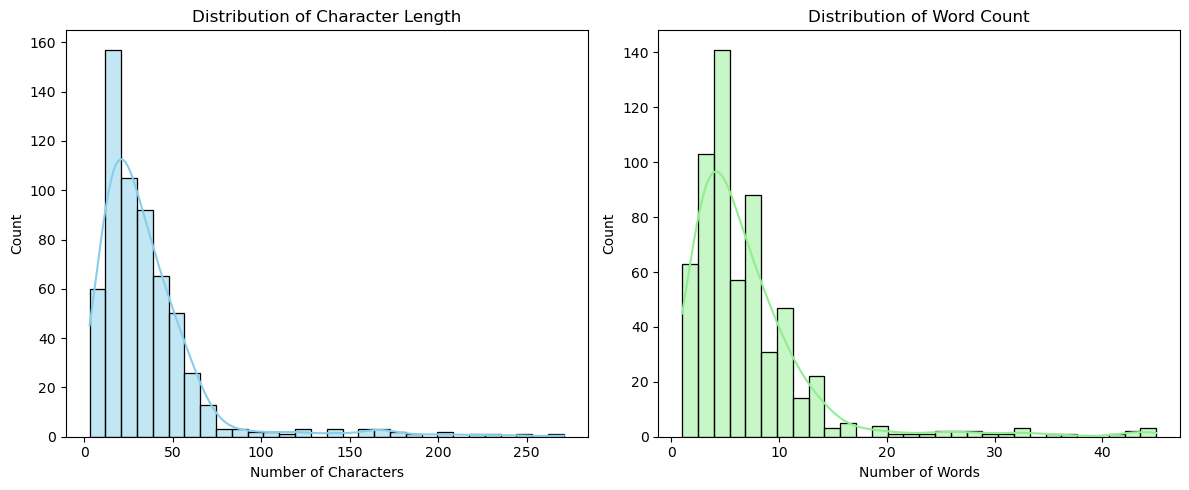

In [14]:
df_text_only['text_length'] = df_text_only['text'].astype(str).apply(len)
df_text_only['word_count'] = df_text_only['text'].astype(str).apply(lambda x: len(x.split()))

# plot text length distribution
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_text_only['text_length'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Character Length')
plt.xlabel('Number of Characters')

plt.subplot(1, 2, 2)
sns.histplot(df_text_only['word_count'], bins=30, kde=True, color='lightgreen')
plt.title('Distribution of Word Count')
plt.xlabel('Number of Words')
plt.tight_layout()
plt.show()

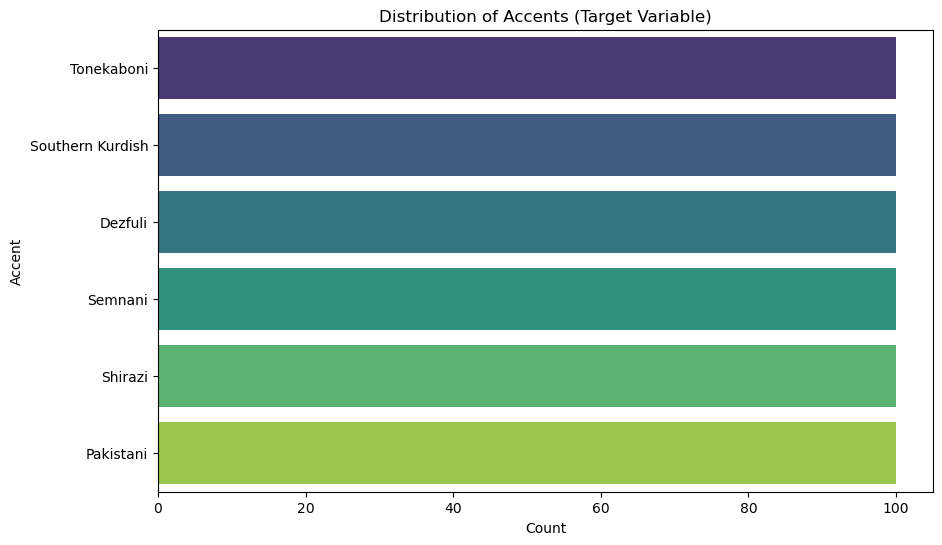

In [15]:
#plot target counts
plt.figure(figsize=(10, 6))
sns.countplot(data=df_text_only, y='accent', order=df_text_only['accent'].value_counts().index, palette='viridis', hue='accent', legend=False)
plt.title('Distribution of Accents (Target Variable)')
plt.xlabel('Count')
plt.ylabel('Accent')
plt.show()

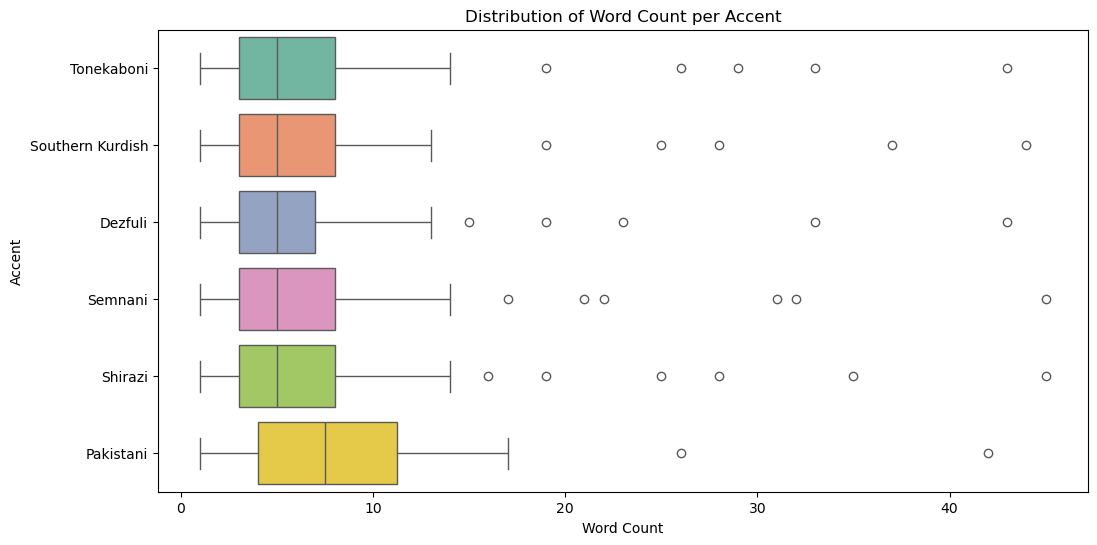

In [ ]:
# plot distribution of word count per accent
plt.figure(figsize=(12, 6))
sns.boxplot(x='word_count', y='accent', data=df_text_only, palette='Set2', hue='accent', legend=False)
plt.title('Distribution of Word Count per Accent')
plt.xlabel('Word Count')
plt.ylabel('Accent')
plt.show()

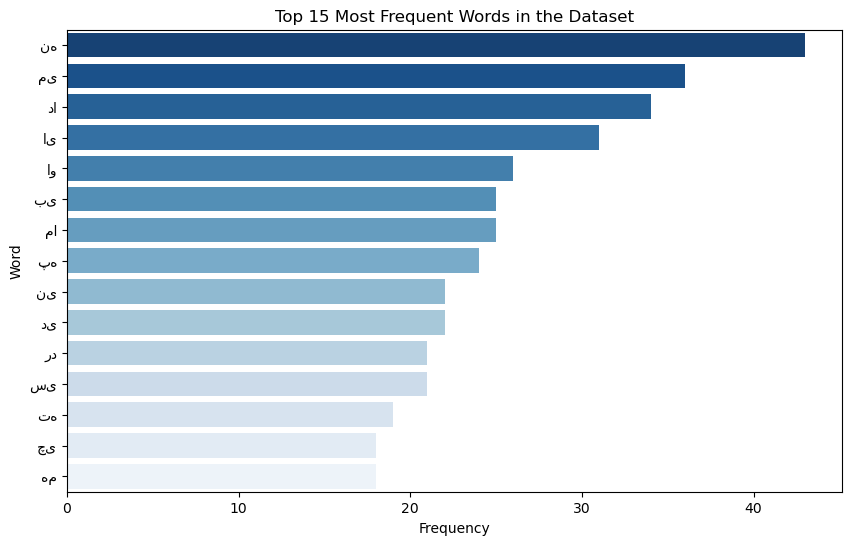

In [18]:
# plot top 15 most frequent words in dataset

# define some persian stop words 
persian_stop_words = ['با', 'به', 'که', 'تا', 'و', 'در', 'از']

def get_top_n_words(corpus, n=None):
    vec = CountVectorizer(stop_words=persian_stop_words).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

top_words = get_top_n_words(df_text_only['text'], n=15)

df_top_words = pd.DataFrame(top_words, columns=['Word', 'Frequency'])

plt.figure(figsize=(10, 6))
sns.barplot(x='Frequency', y='Word', data=df_top_words, palette='Blues_r', hue='Word', legend=False)
plt.title('Top 15 Most Frequent Words in the Dataset')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.show()


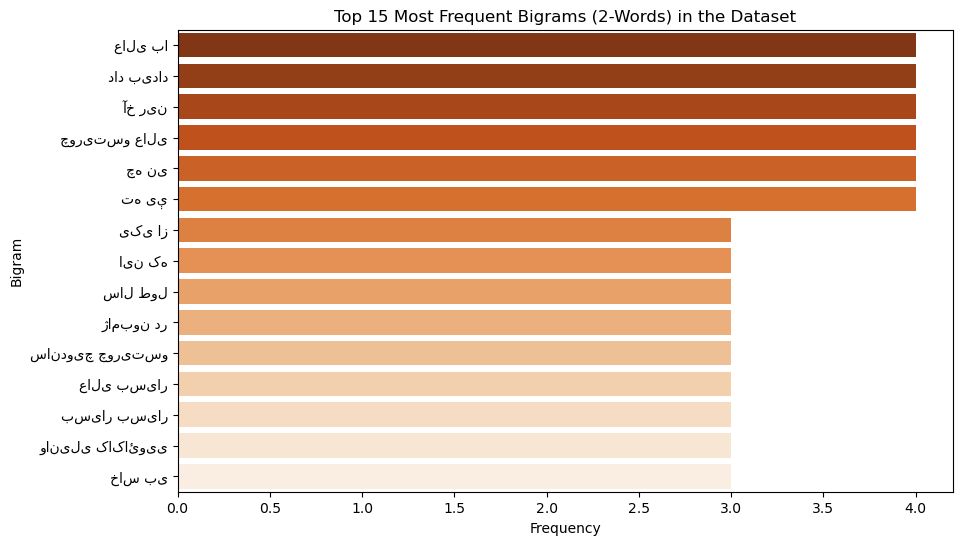

In [19]:
# plot top 15 most frequent bigrams
def get_top_n_bigrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(2, 2)).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

top_bigrams = get_top_n_bigrams(df_text_only['text'], n=15)
df_top_bigrams = pd.DataFrame(top_bigrams, columns=['Bigram', 'Frequency'])

plt.figure(figsize=(10, 6))
sns.barplot(x='Frequency', y='Bigram', data=df_top_bigrams, palette='Oranges_r', hue='Bigram', legend=False)
plt.title('Top 15 Most Frequent Bigrams (2-Words) in the Dataset')
plt.xlabel('Frequency')
plt.ylabel('Bigram')
plt.show()


In [20]:
# clean text a little
def clean_persian_text(text):
    if not isinstance(text, str):
        return ""
    
    # replace Arabic characters with Persian equivalents
    text = text.replace('ي', 'ی').replace('ك', 'ک')
    # replace zero-width non-joiner with space
    text = text.replace('\u200c', ' ')
    # remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

df_text_only['cleaned_text'] = df_text_only['text'].apply(clean_persian_text)

In [21]:
# create train, valid and test sets
label_encoder = LabelEncoder()

X = df_text_only['cleaned_text']
y = label_encoder.fit_transform(df_text_only['accent'])

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Total dataset size: {len(df)}")
print(f"Training set size:   {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Validation set size: {len(X_val)} ({len(X_val)/len(df)*100:.1f}%)")
print(f"Test set size:       {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")


Total dataset size: 700
Training set size:   480 (68.6%)
Validation set size: 60 (8.6%)
Test set size:       60 (8.6%)


### <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">بخش ۲: توکنایز کردن متون و ساخت واژه‌نامه (Tokenization & Vocabulary)</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
مدل‌های یادگیری ماشین و شبکه‌های عصبی نمی‌توانند متون خام را به‌طور مستقیم پردازش کنند. بنابراین، باید جملات را به واحدهای کوچکتری به نام «توکن» (Token) بشکنیم و سپس هر توکن را به یک شناسه عددی (Index) منحصربه‌فرد نگاشت کنیم.
<br><br>
<b>وظایف شما در این بخش:</b>
<ol>
    <li><b>ساخت واژه‌نامه (Vocabulary):</b> یک دیکشنری (Dictionary) بسازید که هر توکنِ یکتا در دادگان را به یک عدد صحیح اختصاص دهد. 
        <br><i>نکته بسیار مهم:</i> حتماً دو توکن ویژه <code>[PAD]</code> (برای هم‌طول‌سازی جملات، معمولاً با شناسه ۰) و <code>[UNK]</code> (برای کلمات خارج از واژه‌نامه، معمولاً با شناسه ۱) را در ابتدای واژه‌نامه خود تعریف کنید.</li>
    <li><b>توکنایز کردن:</b> تابعی بنویسید که متن پیش‌پردازش‌شده را به لیستی از توکن‌ها تبدیل کند. برای سادگی می‌توانید از جداکننده فاصله (Whitespace) استفاده کنید (مثلاً متد <code>split()</code>). با این حال، استفاده از توکنایزرهای پیشرفته‌تر (مانند توکنایزر <code>Hazm</code>، <code>ParsBERT</code> یا توکنایزرهای مبتنی بر زیرکلمه) می‌تواند دقت مدل شما را، به‌ویژه در برخورد با گویش‌ها و لهجه‌های مختلف این دیتاست، بهبود بخشد و امتیاز تشویقی دارد.</li>
    <li><b>تبدیل متن به شناسه (Encoding):</b> با استفاده از واژه‌نامه، تمام جملات دیتاست را به دنباله‌ای از اعداد تبدیل کنید. کلماتی که در واژه‌نامه وجود ندارند باید به شناسه <code>[UNK]</code> تبدیل شوند.</li>
</ol>
</div>

In [23]:
# tokenization using ParsBERT
# here we won't need to add PAD_TOKEN, UNK_TOKEN and word2idx, idx2word

tokenizer_name = "HooshvareLab/bert-base-parsbert-uncased"
tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)

def tokenize(text):
    if not isinstance(text, str):
        return []
    return tokenizer.tokenize(text)

def encode_text(text):
    if not isinstance(text, str):
        return []
    return tokenizer.encode(text, add_special_tokens=True)

# this part is done of df_text_only just to show the validation
df_text_only['tokens'] = df_text_only['cleaned_text'].apply(tokenize)

df_text_only['encoded_text'] = df_text_only['cleaned_text'].apply(encode_text)

print(f"ParsBERT Vocabulary Size: {tokenizer.vocab_size}")

sample_idx = 0
print("\n--- Sample Encoding ---")
print("Original Text: ", df_text_only['cleaned_text'].iloc[sample_idx])
print("Tokenized:     ", df_text_only['tokens'].iloc[sample_idx])
print("Encoded IDs:   ", df_text_only['encoded_text'].iloc[sample_idx])
print("Decoded back:  ", tokenizer.decode(df_text_only['encoded_text'].iloc[sample_idx]))

ParsBERT Vocabulary Size: 100000

--- Sample Encoding ---
Original Text:  داره بوشُم
Tokenized:      ['داره', 'بوش', '##م']
Encoded IDs:    [2, 11723, 6140, 1155, 4]
Decoded back:   [CLS] داره بوشم [SEP]


In [24]:
print(tokenizer.pad_token)
print(tokenizer.unk_token)

print(tokenizer.pad_token_id)
print(tokenizer.unk_token_id)

[PAD]
[UNK]
0
1


### <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">بخش ۳: ساخت  Dataset و DataLoader برای پای‌تورچ</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
اکنون هدف ما پیش‌بینی <b>لهجه (Accent)</b> گوینده از روی متن است. شبکه‌های عصبی در PyTorch برای دریافت داده‌ها نیازمند ساختارهایی به نام <b>تنسور (Tensor)</b> و ماتریس‌هایی با ابعاد یکسان هستند. 
<br><br>
از آنجایی که طول جملات ما با هم تفاوت دارد، باید پیش از ارسال آن‌ها به مدل، فرآیند <b>هم‌طول‌سازی (Padding & Truncation)</b> را انجام دهیم. به این صورت که یک طول بیشینه (مثلاً <code>max_len = 30</code>) در نظر می‌گیریم؛ جملات طولانی‌تر را قطع می‌کنیم و به انتهای جملات کوتاه‌تر توکن <code>[PAD]</code> اضافه می‌کنیم تا همگی هم‌اندازه شوند.
<br><br>
<b>وظایف شما در این بخش:</b>
<ol>
    <li>کلاس سفارشی <code>AccentDataset</code> را تکمیل کنید. در متد <code>__getitem__</code>، عملیات Truncation و Padding را روی لیست توکن‌ها اعمال کرده و هر دو خروجی (متن و برچسب لهجه) را به <code>torch.tensor</code> با نوع داده‌ی <code>long</code> تبدیل کنید.</li>
    <li>با استفاده از داده‌های آموزش و آزمون (که در مراحل پیشین جدا کرده‌اید)، دو شیء از این کلاس بسازید.</li>
    <li>اشیای <code>train_loader</code> و <code>test_loader</code> را بسازید (مقدار <code>batch_size</code> را ترجیحاً 8 در نظر بگیرید). اطمینان حاصل کنید که دیتالودر مربوط به آموزش، داده‌ها را بُر می‌زند (<code>shuffle=True</code>).</li>
</ol>
</div>

In [25]:
class AccentDataset(Dataset):
    def __init__(self, encoded_texts, accent_labels, max_len=30):

        self.texts = encoded_texts.tolist() if hasattr(encoded_texts, 'tolist') else encoded_texts
        self.labels = accent_labels.tolist() if hasattr(accent_labels, 'tolist') else accent_labels
        self.max_len = max_len
        self.pad_token_id = 0 

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text_seq = self.texts[idx]
        label = self.labels[idx]

        # truncate
        if len(text_seq) > self.max_len:
            text_seq = text_seq[:self.max_len]
        
        # padding
        else:
            padding_length = self.max_len - len(text_seq)
            text_seq = text_seq + [self.pad_token_id] * padding_length

        text_tensor = torch.tensor(text_seq, dtype=torch.long)
        label_tensor = torch.tensor(label, dtype=torch.long)
        
        return text_tensor, label_tensor


X_train_encoded = X_train.apply(encode_text)
X_val_encoded = X_val.apply(encode_text)
X_test_encoded = X_test.apply(encode_text)

train_dataset = AccentDataset(X_train_encoded, y_train, max_len=30)
valid_dataset = AccentDataset(X_val_encoded, y_val, max_len=30)
test_dataset = AccentDataset(X_test_encoded, y_test, max_len=30)

BATCH_SIZE = 8
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


if train_loader is not None:
    sample_batch_texts, sample_batch_labels = next(iter(train_loader))
    print(f"Batch Texts Shape: {sample_batch_texts.shape}")
    print(f"Batch Labels Shape: {sample_batch_labels.shape}")
    print("\nSample Label Tensor:", sample_batch_labels[:5])
else:
    print("DataLoaders are not initialized yet.")


Batch Texts Shape: torch.Size([8, 30])
Batch Labels Shape: torch.Size([8])

Sample Label Tensor: tensor([4, 5, 3, 4, 4])


### <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">بخش ۴: معماری شبکه عصبی ابداعی (Parity-Net)</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
در این مرحله باید شبکه‌ی عصبی خود را طراحی کنید. ما از یک معماری به نام <b>Parity-Net</b> استفاده می‌کنیم. در این شبکه، مدل برای کلماتی که تعداد حروفشان زوج است از یک لایه Embedding، و برای کلماتی که تعداد حروفشان فرد است از یک لایه Embedding دیگر استفاده می‌کند.
<br><br>
<b>قوانین ساخت این معماری (بسیار ساده):</b>
<ol>
    <li><b>تعریف لایه‌ها:</b> در متد <code>__init__</code>، دو لایه Embedding مجزا بسازید:
        <ul>
            <li><code>emb_even</code>: با سایز ورودی برابر با کل واژه‌نامه و بُعد خروجی <b>64</b>.</li>
            <li><code>emb_odd</code>: با سایز ورودی برابر با کل واژه‌نامه و بُعد خروجی <b>64</b>.</li>
        </ul>
    </li>
    <li><b>جدا کردن ایندکس‌ها:</b> شما باید در متد سازنده، لیست ایندکس‌هایی که مربوط به کلمات زوج هستند و لیست ایندکس‌هایی که مربوط به کلمات فرد هستند را پیدا کنید (با یک حلقه <code>for</code> ساده روی <code>word2idx</code>).</li>
    <li><b>فریز کردن متقاطع (Cross-Freezing):</b> برای اینکه لایه زوج فقط کلمات زوج را یاد بگیرد، باید وزن‌های (Weights) مربوط به کلمات فرد را در <code>emb_even</code> <b>صفر و فریز</b> کنید. بالعکس، در <code>emb_odd</code>، وزن‌های مربوط به کلمات زوج را صفر و فریز کنید. (راهنمایی: می‌توانید مستقیماً به <code>emb.weight.data</code> دسترسی پیدا کنید).</li>
    <li><b>جریان داده (Forward Pass):</b> 
        <ul>
            <li>ورودی <code>input_ids</code> را به هر دو امبدینگ بدهید. (چون وزن‌های نامربوط صفر شده‌اند، خروجی <code>emb_even</code> برای کلمات فرد تماماً صفر خواهد بود).</li>
            <li>روی بُعد توکن‌ها (طول جمله) میانگین (mean) بگیرید.</li>
            <li>دو بردار به دست آمده را با هم جمع (Sum) کنید.</li>
            <li>بردار نهایی را از یک لایه خطی (Linear) عبور دهید تا خروجی کلاس‌ها تولید شود.</li>
        </ul>
    </li>
</ol>
</div>

In [26]:
# since i'm using ParsBERT, the code here is a little different from given template

class ParityNet(nn.Module):
    def __init__(self, vocab, num_classes, embedding_dim=64, padding_idx=0):
        super(ParityNet, self).__init__()
        
        vocab_size = len(vocab)
        
        self.emb_even = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.emb_odd = nn.Embedding(vocab_size, 64, padding_idx=0)
        
        # cross freeze weights
        with torch.no_grad():
            for token, idx in vocab.items():
                # remove ## for accurate count
                clean_token = token.replace('##', '')
                
                if len(clean_token) % 2 == 0:
                    # it's even so set the weigght in emb_odd to 0
                    self.emb_odd.weight.data[idx] = 0.0
                else:
                    # it's odd so set the weigght in emb_even to 0
                    self.emb_even.weight.data[idx] = 0.0
                    
        self.fc = nn.Linear(embedding_dim, num_classes)

    def forward(self, input_ids):
        # input_ids shape: (Batch, SeqLen)
        
        e_emb = self.emb_even(input_ids)  # (Batch, SeqLen, 64)
        o_emb = self.emb_odd(input_ids)   # (Batch, SeqLen, 64)
        
        e_pooled = e_emb.mean(dim=1)      # (Batch, 64)
        o_pooled = o_emb.mean(dim=1)      # (Batch, 64)
        
        combined = e_pooled + o_pooled    # (Batch, 64)
        
        out = self.fc(combined)           # (Batch, num_classes)
        
        return out

# new validation code because of using ParsBERT
vocab = tokenizer.get_vocab()

num_classes = 6
model = ParityNet(vocab=vocab, num_classes=num_classes, embedding_dim=64, padding_idx=0)

dummy_input = torch.randint(low=0, high=len(vocab), size=(16, 30))

output = model(dummy_input)
print(f"Output shape: {output.shape}")

Output shape: torch.Size([16, 6])


### <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">بخش ۵: حلقه آموزش و ارزیابی (Training Loop & Evaluation)</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
اکنون که مدل ابداعی خود (Parity-Net) را طراحی کرده‌اید، نوبت به آموزش آن می‌رسد. در این مرحله باید مدل را با استفاده از داده‌های آموزش تغذیه کرده و خطای آن را کاهش دهید.
<br><br>
<b>یک پیام مهم در مورد نمره‌دهی:</b>
هدف اصلی این تمرین، پیاده‌سازی صحیح معماری، جریان داده‌ها و درک مفاهیم است. از آنجایی که فرض بر این است که شما از <b>CPU</b> برای پردازش استفاده می‌کنید، انتظار نداریم که به بالاترین دقت‌های ممکن برسید. <b>در صورت پیاده‌سازی درست مراحل قبلی و اجرای موفقیت‌آمیز مدل حتی برای حداقل ۵ اِپاک (Epoch)، نمره کامل این بخش را دریافت خواهید کرد.</b> البته، رسیدن به دقت‌های بالاتر (با تنظیم بهتر هایپرپارامترها یا با استفاده درست‌تر از دادگانی که در اختیار داشتید) دارای امتیاز تشویقی است.
<br><br>
<b>وظایف شما در این بخش:</b>
<ol>
    <li>مدل <code>ParityNet</code> را مقداردهی اولیه کنید (کلاس آن را فراخوانی کنید).</li>
    <li>تابع خطا (Loss Function) را از نوع <code>CrossEntropyLoss</code> انتخاب کنید و بهینه‌ساز (Optimizer) را روی <code>Adam</code> یا <code>SGD</code> تنظیم کنید.</li>
    <li><b>حلقه آموزش (Training Loop):</b> یک حلقه برای تعداد مشخصی Epoch بنویسید (مثلاً ۵ تا ۱۰ اِپاک). در هر اِپاک:
        <ul>
            <li>داده‌ها را از <code>train_loader</code> بخوانید.</li>
            <li>گرادیان‌ها را صفر کنید (<code>optimizer.zero_grad()</code>).</li>
            <li>داده‌ها را به مدل بدهید (Forward Pass) و مقدار خطا (Loss) را محاسبه کنید.</li>
            <li>خطا را در شبکه به عقب پخش کنید (<code>loss.backward()</code>) و وزن‌ها را آپدیت کنید (<code>optimizer.step()</code>).</li>
        </ul>
    </li>
    <li><b>ارزیابی مدل (Evaluation):</b> پس از پایان آموزش، مدل را در حالت ارزیابی (<code>model.eval()</code>) قرار داده و با استفاده از معیارهای ارزیابی مناسب عملکرد مدل را بسنجید.</li>
</ol>
</div>

In [27]:
num_classes = 6
vocab = tokenizer.get_vocab()
model = ParityNet(vocab=vocab, num_classes=num_classes, embedding_dim=64, padding_idx=0)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 20
print('Training and Validation: ')
for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0
    
    for batch_texts, batch_labels in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_texts)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
    
    avg_train_loss = total_train_loss / len(train_loader)
    
    model.eval()
    total_val_loss = 0
    val_preds = []
    val_targets = []
    
    with torch.no_grad():
        for val_texts, val_labels in valid_loader:
            val_outputs = model(val_texts)
            val_loss = criterion(val_outputs, val_labels)
            total_val_loss += val_loss.item()
            
            _, predicted = torch.max(val_outputs, dim=1)
            val_preds.extend(predicted.tolist())
            val_targets.extend(val_labels.tolist())
            
    avg_val_loss = total_val_loss / len(valid_loader)
    val_accuracy = accuracy_score(val_targets, val_preds)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_accuracy * 100:.2f}%")


print('\nFinal Evaluation on Test Set')
model.eval()

predictions = []
gold_labels = []

with torch.no_grad():
    for batch_texts, batch_labels in test_loader:
        outputs = model(batch_texts)
        _, predicted_classes = torch.max(outputs, dim=1)
        predictions.extend(predicted_classes.tolist())
        gold_labels.extend(batch_labels.tolist())

accuracy = accuracy_score(gold_labels, predictions)
print(f"Accuracy on Test Set: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(gold_labels, predictions))


Training and Validation: 
Epoch 1/20 | Train Loss: 1.7588 | Val Loss: 1.7271 | Val Acc: 31.67%
Epoch 2/20 | Train Loss: 1.6600 | Val Loss: 1.6525 | Val Acc: 38.33%
Epoch 3/20 | Train Loss: 1.5652 | Val Loss: 1.5761 | Val Acc: 41.67%
Epoch 4/20 | Train Loss: 1.4701 | Val Loss: 1.5056 | Val Acc: 45.00%
Epoch 5/20 | Train Loss: 1.3784 | Val Loss: 1.4378 | Val Acc: 45.00%
Epoch 6/20 | Train Loss: 1.2901 | Val Loss: 1.3803 | Val Acc: 50.00%
Epoch 7/20 | Train Loss: 1.2069 | Val Loss: 1.3280 | Val Acc: 56.67%
Epoch 8/20 | Train Loss: 1.1268 | Val Loss: 1.2808 | Val Acc: 55.00%
Epoch 9/20 | Train Loss: 1.0494 | Val Loss: 1.2393 | Val Acc: 56.67%
Epoch 10/20 | Train Loss: 0.9744 | Val Loss: 1.2006 | Val Acc: 65.00%
Epoch 11/20 | Train Loss: 0.9005 | Val Loss: 1.1665 | Val Acc: 68.33%
Epoch 12/20 | Train Loss: 0.8305 | Val Loss: 1.1358 | Val Acc: 68.33%
Epoch 13/20 | Train Loss: 0.7627 | Val Loss: 1.1059 | Val Acc: 70.00%
Epoch 14/20 | Train Loss: 0.6994 | Val Loss: 1.0801 | Val Acc: 70.00%
Epo

In [28]:
print(f"Accuracy on Test Set: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(gold_labels, predictions))

Accuracy on Test Set: 60.00%

Classification Report:
              precision    recall  f1-score   support

           0       0.38      0.60      0.46        10
           1       0.90      0.90      0.90        10
           2       0.70      0.70      0.70        10
           3       0.38      0.30      0.33        10
           4       1.00      0.70      0.82        10
           5       0.44      0.40      0.42        10

    accuracy                           0.60        60
   macro avg       0.63      0.60      0.61        60
weighted avg       0.63      0.60      0.61        60



In [29]:
label_encoder.classes_

array(['Dezfuli', 'Pakistani', 'Semnani', 'Shirazi', 'Southern Kurdish',
       'Tonekaboni'], dtype=object)

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
<b>ارزیابی و تحلیل شما بابت نتایج به دست آمده چیست؟ (در خط بعدی همین markdown بنویسید.)</b>
<br><br>
پاسخ شما:
دقت کلی مدل روی مجموعه تست 66.67% است که عملکرد متوسط رو به بالایی را نشان می دهد (البته که دیتاست ها همه بسیار کوچک هستند پس چنین نتایجی مورد انتظار است). طبق نتایج، مدل در تشخیص لهجه‌های پاکستانی و سمنانی و کردی جنوبی عملکردی عالی دارد و به نظر می‌آید که الگو های زبانی آن‌ ها را به خوبی یاد گرفته است. اما نقطه ضعف مدل در تفکیک لهجه‌های شیرازی و دزفولی است
</div>

### <div dir="rtl" style="text-align: right; font-family: Vazir, Tahoma, sans-serif;">بخش ۶: تحلیل خطا (Error Analysis) - بخش امتیازی و تحلیلی</div>

<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
در دنیای واقعی پردازش زبان طبیعی (NLP)، رسیدن به یک دقت بالا پایان کار نیست. مهندسان ماشین‌لرنینگ همیشه بررسی می‌کنند که مدلشان در چه مواقعی <b>اشتباه</b> می‌کند تا بتوانند نقاط ضعف آن را پوشش دهند (مثلاً شاید مدل با یک گویش خاص مشکل داشته باشد یا توکنایزر به درستی کار نکرده باشد).
<br><br>
<b>وظایف شما در این بخش:</b>
<ol>
    <li><b>استخراج خطاها (کدنویسی):</b> کدی بنویسید که ۳ جمله‌ای را که مدل شما روی آن‌ها <b>بیشترین میزان اطمینان در اشتباه کردن</b> را داشته است پیدا کند. (یعنی مدل با احتمال بالا مثلاً ۹۰٪ گفته این لهجه گیلکی است، اما در واقعیت لری بوده است).</li>
    <li>چاپ نتایج شامل: متن اصلی جمله، لهجه واقعی (True Label) و لهجه پیش‌بینی‌شده توسط مدل (Predicted Label) همراه با احتمال پیش‌بینی (Confidence).</li>
    <li><b>تحلیل زبان‌شناختی (متنی):</b> در یک سلول Markdown زیرِ کدهایتان، به طور خلاصه تحلیل کنید که <b>چرا</b> مدل در این جملات اشتباه کرده است؟ 
        <ul>
            <li>آیا کلمات مشترکی بین این دو لهجه وجود دارد؟</li>
            <li>آیا طول جمله (خیلی کوتاه یا خیلی بلند بودن) باعث خطا در میانگین‌گیری و جمع‌گیری (Sum) بردارهای زوج و فرد شده است؟</li>
            <li>آیا نویزی در دیتاست (برچسب‌گذاری اشتباه توسط انسان) وجود دارد؟</li>
        </ul>
    </li>
</ol>
</div>

In [30]:
print("--- Top 3 Model Errors ---")

errors = []

model.eval()

with torch.no_grad():
    for batch_texts, batch_labels in test_loader:
        
        logits = model(batch_texts)
        
        probs = F.softmax(logits, dim=1)
        
        max_probs, predicted_labels = torch.max(probs, dim=1)
        
        for i in range(len(batch_labels)):
            if predicted_labels[i] != batch_labels[i]:
                text_tokens = batch_texts[i].tolist()
                text = tokenizer.decode(text_tokens, skip_special_tokens=True)
                
                true_label = batch_labels[i].item()
                pred_label = predicted_labels[i].item()
                confidence = max_probs[i].item()
                
                errors.append({
                    'text': text,
                    'true_label': true_label,
                    'pred_label': pred_label,
                    'confidence': confidence
                })

errors.sort(key=lambda x: x['confidence'], reverse=True)


for idx, error in enumerate(errors[:3]):
    true_name = label_encoder.inverse_transform([error['true_label']])[0]
    pred_name = label_encoder.inverse_transform([error['pred_label']])[0]
    
    print(f"Error #{idx+1}:")
    print(f"Text: {error['text']}")
    print(f"True Label: {true_name} | Predicted Label: {pred_name}")
    print(f"Confidence: {error['confidence'] * 100:.2f}%\n")

--- Top 3 Model Errors ---
Error #1:
Text: پنج به علاوه چار به علاوه سه
True Label: Tonekaboni | Predicted Label: Shirazi
Confidence: 65.16%

Error #2:
Text: من چوی نمخورم
True Label: Shirazi | Predicted Label: Dezfuli
Confidence: 57.82%

Error #3:
Text: غلام با ابر سیا اومد و دختره به قصر شاه پریون برد.
True Label: Shirazi | Predicted Label: Tonekaboni
Confidence: 51.97%



<div dir="rtl" style="text-align: right; line-height: 2; font-family: Vazir, Tahoma, sans-serif;">
<b>تحلیل خطاهای مدل:</b>
<br><br>
<i>(تحلیل خود را در قالب چند خط اینجا بنویسید. به کلمات خاص یا ساختار جملات استخراج‌شده در سلول قبل دقت کنید.)</i>
<br><br>
پاسخ شما:
به نظر عامل اصلی این اشتباهات، هم پوشانی بالا در واژگان و استفاده از کلمه های محاوره ای مشترک بین لهجه ها باشد. شاید برخی تغییرات آوایی مثل تبدیل چای به چوی یا برخی اصطلاحات مثل خدا دونه در لهجه های شیرازی و دزفولی مشترک است. اما ارور اول تقریبا تمام کلمات فارسی است (حتی چار که گفتار در فارسی چهار است) و به نظر واژگان تنکابنی ندارد که البته اینجا احتمالا مشکل از داده ها و لیبل زدن به آن ها باشد. هر 3 جمله بالا، بسیار کوتاه هستند که به علت ساختار مدل ParityNet است که در آن اطلاعات توالی از بین می‌رود. زیرا روی بعد طول جمله میانگین می‌گیرد و ترتیب نادیده گرفته می شود. چون توالی از بین رفته، مدل باید بتواند کلمات خاص را پیدا کند و در جملات کوتاه تعداد کلمات کم است (پس احتمال وجود کلمه خاص بسیار کم است) و این جمله ها دارای کلمه های مشترک بین لهجه ها هستند.
</div>